<a href="https://colab.research.google.com/github/Divyasharma1910/Image_processing/blob/main/Assignment_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from PIL import Image


Saving space.jpg to space.jpg


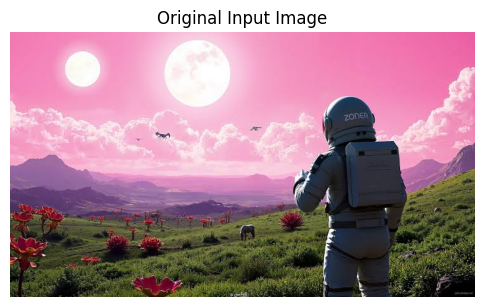

In [ ]:

uploaded = files.upload()

image_path = next(iter(uploaded))

# Read the image and convert BGR to RGB
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display the input image
plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title("Original Input Image")
plt.axis("off")
plt.show()


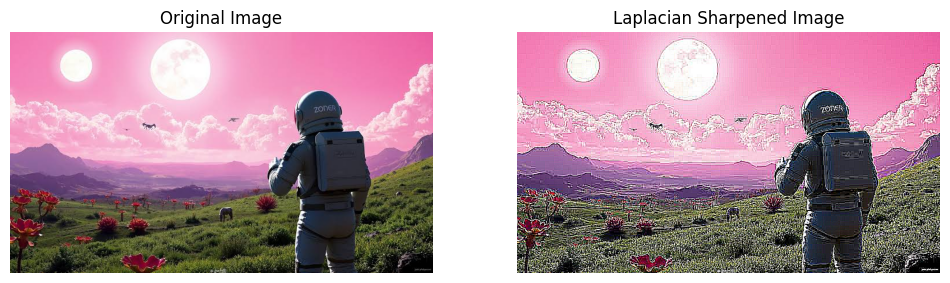

In [ ]:

# Apply the Laplacian filter
laplacian = cv2.Laplacian(image, cv2.CV_64F, ksize=3)

# Sharpen the image using the Laplacian
laplacian_sharpened = np.clip(
    image.astype(np.float64) - laplacian, 0, 255
).astype(np.uint8)

# Display the result
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(laplacian_sharpened)
plt.title("Laplacian Sharpened Image")
plt.axis("off")

plt.show()


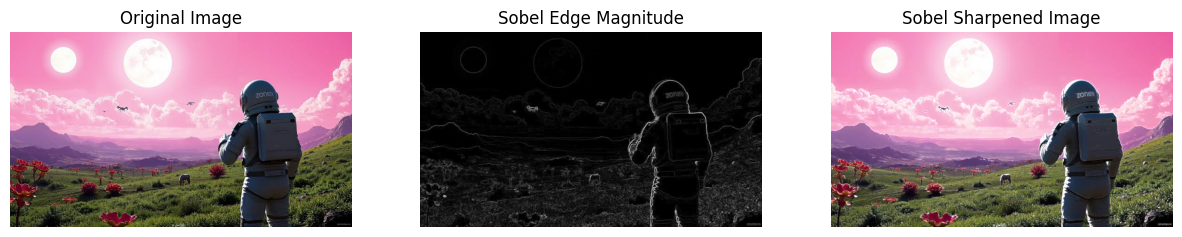

In [ ]:

# Convert the image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Calculate horizontal and vertical gradients
sobel_x = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)

# Calculate gradient magnitude
sobel_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)

# Normalize the gradient magnitude to 0-255
sobel_edges = cv2.normalize(
    sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Sharpen the original image using Sobel edges
sobel_sharpened = cv2.addWeighted(
    image, 1.0, cv2.cvtColor(sobel_edges, cv2.COLOR_GRAY2RGB),
    0.7, 0
)

# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sobel_edges, cmap="gray")
plt.title("Sobel Edge Magnitude")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sobel_sharpened)
plt.title("Sobel Sharpened Image")
plt.axis("off")

plt.show()


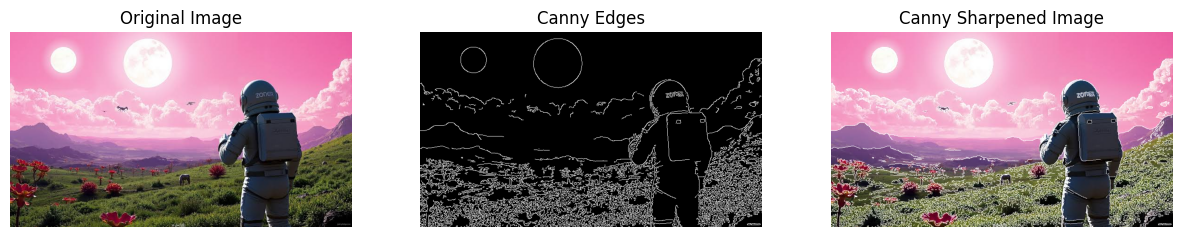

In [ ]:

# Detect edges using Canny
canny_edges = cv2.Canny(gray, 100, 200)

# Convert the single-channel edges to RGB
canny_edges_rgb = cv2.cvtColor(canny_edges, cv2.COLOR_GRAY2RGB)

# Sharpen the original image using Canny edges
canny_sharpened = cv2.addWeighted(
    image, 1.0, canny_edges_rgb, 0.7, 0
)

# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(canny_edges, cmap="gray")
plt.title("Canny Edges")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(canny_sharpened)
plt.title("Canny Sharpened Image")
plt.axis("off")

plt.show()


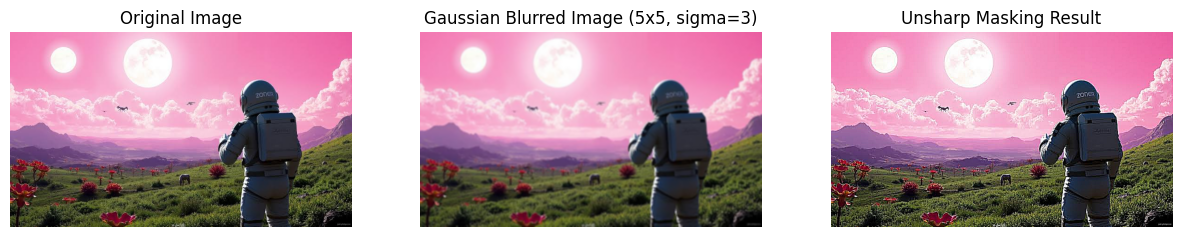

In [ ]:

# Blur the image using the required Gaussian filter
blurred = cv2.GaussianBlur(image, (5, 5), 3)

# Calculate the unsharp mask
mask = image.astype(np.float32) - blurred.astype(np.float32)

# Add the mask back to the original image
amount = 1.5
unsharp_sharpened = np.clip(
    image.astype(np.float32) + amount * mask, 0, 255
).astype(np.uint8)

# Display the results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(blurred)
plt.title("Gaussian Blurred Image (5x5, sigma=3)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(unsharp_sharpened)
plt.title("Unsharp Masking Result")
plt.axis("off")

plt.show()


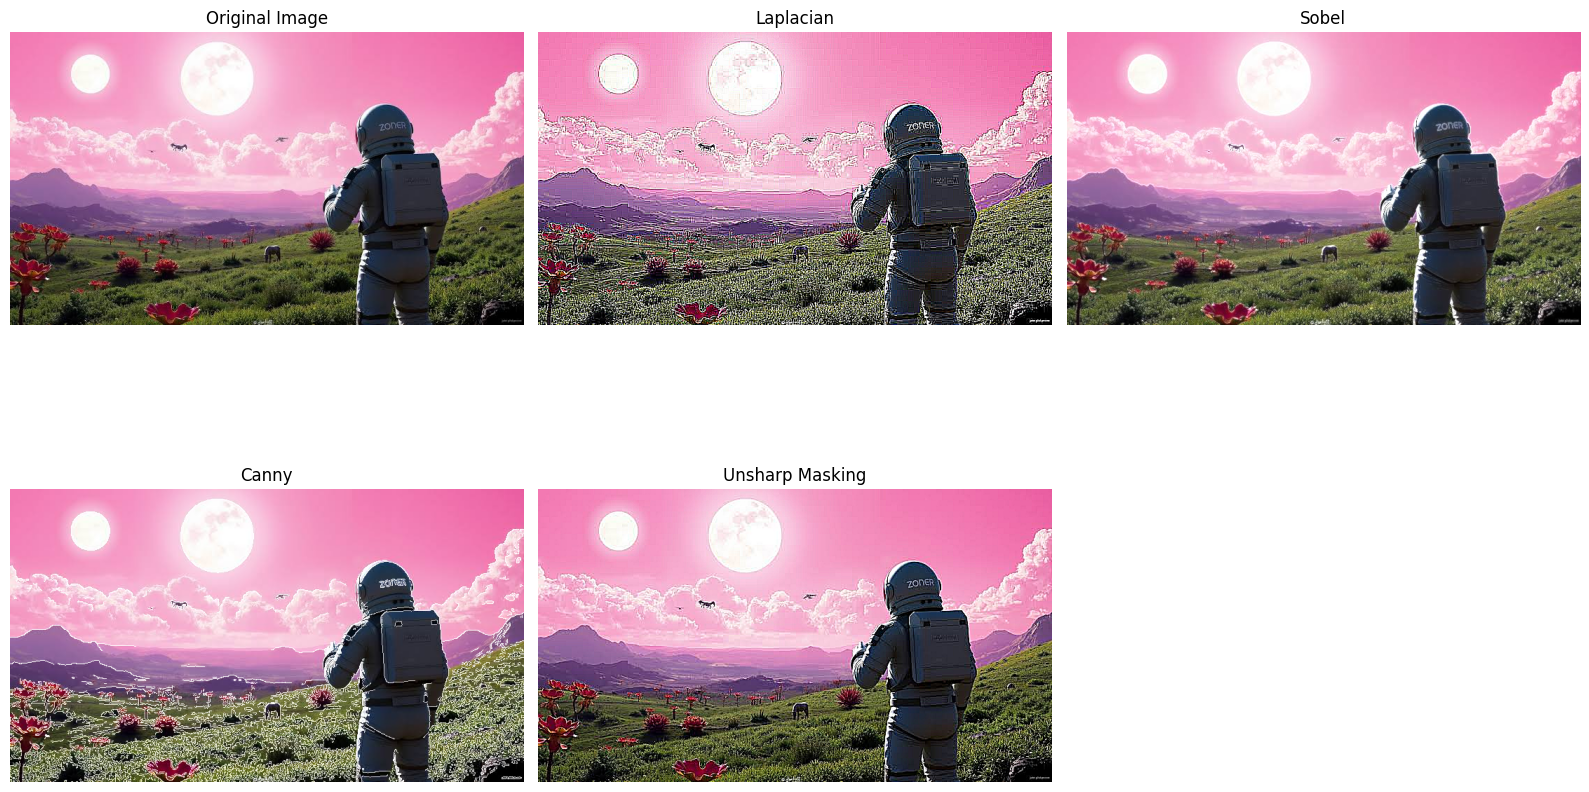

In [ ]:

# Compare all methods
results = [
    ("Original Image", image),
    ("Laplacian", laplacian_sharpened),
    ("Sobel", sobel_sharpened),
    ("Canny", canny_sharpened),
    ("Unsharp Masking", unsharp_sharpened)
]

plt.figure(figsize=(16, 10))

for i, (title, result) in enumerate(results):
    plt.subplot(2, 3, i + 1)
    plt.imshow(result)
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()


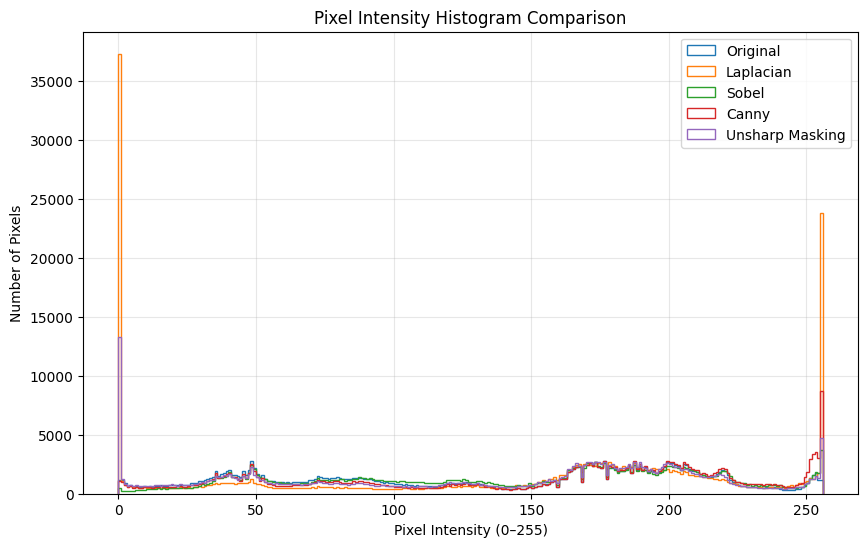

In [ ]:

# Convert images to grayscale for histogram comparison
original_gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
lap_gray = cv2.cvtColor(laplacian_sharpened, cv2.COLOR_RGB2GRAY)
sobel_gray = cv2.cvtColor(sobel_sharpened, cv2.COLOR_RGB2GRAY)
canny_gray = cv2.cvtColor(canny_sharpened, cv2.COLOR_RGB2GRAY)
unsharp_gray = cv2.cvtColor(unsharp_sharpened, cv2.COLOR_RGB2GRAY)

# Plot pixel intensity histograms
plt.figure(figsize=(10, 6))

for img, label in [
    (original_gray, "Original"),
    (lap_gray, "Laplacian"),
    (sobel_gray, "Sobel"),
    (canny_gray, "Canny"),
    (unsharp_gray, "Unsharp Masking")
]:
    plt.hist(img.ravel(), bins=256, range=(0, 256),
             histtype="step", label=label)

plt.title("Pixel Intensity Histogram Comparison")
plt.xlabel("Pixel Intensity (0–255)")
plt.ylabel("Number of Pixels")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()
